In [57]:
%load_ext autoreload
%autoreload 2
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


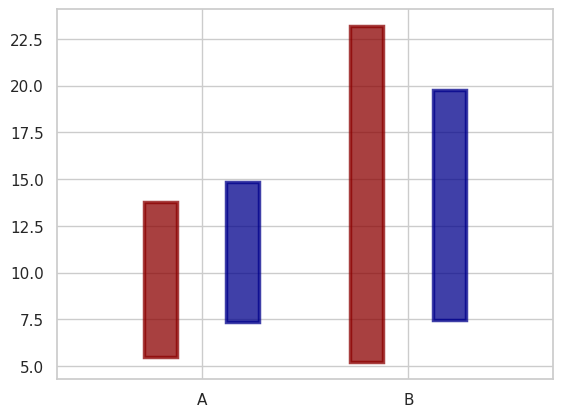

In [33]:
fig, ax = plt.subplots()
groups = df["Group"].unique()
scenarios = df["Scenario"].unique()
#colors = sns.color_palette("Set2", n_colors=len(scenarios))

colors = ["darkred", "darkblue"] 

stats, positions, box_colors = [], [], []
box_width = 0.8 / len(scenarios)

for i, group_name in enumerate(groups):
    for j, scenario in enumerate(scenarios):
        vals = df.loc[
            (df["Group"] == group_name) & (df["Scenario"] == scenario),
            "Value"
        ].dropna()

        if vals.empty:
            continue

        stats.append({
            "label": str(scenario),
            "med": vals.median(),
            "q1": vals.min(),
            "q3": vals.max(),
            "whislo": vals.min(),
            "whishi": vals.max(),
        })
        positions.append(i + 1 + (j - (len(scenarios) - 1) / 2) * box_width)
        box_colors.append(colors[j])

bp = ax.bxp(
    stats, positions=positions, widths=box_width * 0.4,
    patch_artist=True, showfliers=False,
    showcaps=False,
    medianprops={"visible": False},
    whiskerprops={"visible": False},
)
for i, (box, color) in enumerate(zip(bp["boxes"], box_colors)):
    box.set_facecolor(color)
    box.set_edgecolor(color)
    box.set_alpha(0.75)
    box.set_linewidth(2.5)


ax.set_xticks(range(1, len(groups) + 1))
ax.set_xticklabels(groups)
plt.show()

### Files

In [87]:
def check(df,df_result,sc,ts, var,mm='7'):
    #check id meging of df succided:

    realisations=df["realization"].unique()
    regions=df["region"].unique()
    #scenarios=df["scenario"].unique()
    #mid_months=df["mid_month"].unique()
    r=realisations[8]
    rg=regions[3]
    sc=scenarios[1]
    mm=mid_months[2]
    

    match = df_result.loc[
        (df_result["realization"] == r)
        & (df_result["region"] == rg)
        & (df_result["scenario"] == sc)
        & (df_result["mid_month"] == mm),
        f"{var}_{ts}"
    ].copy()
    match_org = df.loc[
        (df["realization"] == r)
        & (df["region"] == rg)
        & (df["scenario"] == sc)
        & (df["mid_month"] == mm),
        f"{var}_{ts}"
    ]

    if match != match_org:
        print('ubs')
    else:
        print (match, match_org)

In [ ]:

var='TG'
season='_sem_' 
keys = ["realization", "region", "mid_month", "scenario"]

wkd=os.getcwd()
wkd
scenarios = ['rcp26','rcp45', 'rcp85']
time_slices = ['1971_2000', '2040_2069', '2070_2099']
for s in scenarios:
    #print(s)
    for t in time_slices:
        #print(t)
        datadirs = glob.glob(os.path.join(wkd, "data", var+season+t+"*"+s+"*"))
        #print(f"Data directories for {s} and {t}: {datadirs}")
        datadirs = [os.path.abspath(path) for path in datadirs]
        df= pd.read_csv(datadirs[0])
        # rename column:
        name=os.path.basename(datadirs[0])
        col_name=name.split('.')[0]
        #print(f"Column name for {s} and {t}: {col_name}")
        df = df.rename(columns={col_name: var+'_'+t})
        df['scenario'] = s
        if t != '1971_2000':
            df_result = df_result.merge(
                df[keys + [var+'_'+t]],
                on=keys,
                how="left",
                validate="one_to_one",
                )
            check(df,df_result,r,rg,s,t,var,mm='7'):
        else:
            df_result=df

df.head(3)
df_result.head(3)



rcp26
1971_2000
Data directories for rcp26 and 1971_2000: ['/home/g/g300047/SCRIPTS/github/udag/data/TG_sem_1971_2000_rcp26_time-mean.csv']
Column name for rcp26 and 1971_2000: TG_sem_1971_2000_rcp26_time-mean
2040_2069
Data directories for rcp26 and 2040_2069: ['/home/g/g300047/SCRIPTS/github/udag/data/TG_sem_2040_2069_rcp26_time-mean.csv']
Column name for rcp26 and 2040_2069: TG_sem_2040_2069_rcp26_time-mean
2070_2099
Data directories for rcp26 and 2070_2099: ['/home/g/g300047/SCRIPTS/github/udag/data/TG_sem_2070_2099_rcp26_time-mean.csv']
Column name for rcp26 and 2070_2099: TG_sem_2070_2099_rcp26_time-mean
rcp45
1971_2000
Data directories for rcp45 and 1971_2000: ['/home/g/g300047/SCRIPTS/github/udag/data/TG_sem_1971_2000_rcp45_time-mean.csv']
Column name for rcp45 and 1971_2000: TG_sem_1971_2000_rcp45_time-mean
2040_2069
Data directories for rcp45 and 2040_2069: ['/home/g/g300047/SCRIPTS/github/udag/data/TG_sem_2040_2069_rcp45_time-mean.csv']
Column name for rcp45 and 2040_2069: T

,realization,region,TG_1971_2000,ci_name,ci_frequency,standard_name,units,mid_month,scenario,TG_2040_2069,TG_2070_2099
0,HYR-5_GERICS_CLMcom-CCLM4-8-17_CCCma-CanESM2_r...,Duisburg_3x3,276.26913,TG,sem,air_temperature,K,1,rcp85,278.61813,279.45710
1,HYR-5_GERICS_CLMcom-CCLM4-8-17_CCCma-CanESM2_r...,Duisburg_3x3,283.14807,TG,sem,air_temperature,K,4,rcp85,284.58878,285.99704
2,HYR-5_GERICS_CLMcom-CCLM4-8-17_CCCma-CanESM2_r...,Duisburg_3x3,291.20430,TG,sem,air_temperature,K,7,rcp85,294.44970,297.36502


In [85]:
df.head(1)

,realization,region,TG_2070_2099,ci_name,ci_frequency,standard_name,units,mid_month,scenario
0,HYR-5_GERICS_CLMcom-CCLM4-8-17_CCCma-CanESM2_r...,Duisburg_3x3,279.4571,TG,sem,air_temperature,K,1,rcp85


In [ ]:
def check(df,def_result):
    #check:
    keys = ["realization", "region", "mid_month", "scenario"]
    realisations=df["realization"].unique()
    regions=df["region"].unique()
    scenarios=df["scenario"].unique()
    mid_months=df["mid_month"].unique()
    r=realisations[8]
    rg=regions[3]
    sc=scenario[1]
    mm=mid_months[2]
    ts=2040_2069

    ts = "2040_2069"   # keep as string
    sc = "rcp85"      # or sc = scenarios[1] if you want to derive it

    match = df_result.loc[
        (df_result["realization"] == r)
        & (df_result["region"] == rg)
        & (df_result["scenario"] == sc)
        & (df_result["mid_month"] == mm),
        f"TG_{ts}"
    ].copy()
    match_org = df.loc[
        (df["realization"] == r)
        & (df["region"] == rg)
        & (df["scenario"] == sc)
        & (df["mid_month"] == mm),
        f"TG_{ts}"
    ]

    if match != match_org:
        print('ubs')
    else:
        print (match, match_org)






KeyError: 'TG_2040_2069'

#### look at files:

In [43]:
import pandas as pd

rr = pd.read_csv(os.path.join(datadir, datafiles[7]))
rr.head(3)

,realization,region,RRm_sem_2040_2069_ssp370_time-mean,ci_name,ci_frequency,standard_name,units,mid_month
0,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,Duisburg_3x3,2.257877,RRm,sem,precipitation,mm day-1,1
1,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,Duisburg_3x3,2.054765,RRm,sem,precipitation,mm day-1,4
2,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,Duisburg_3x3,2.554161,RRm,sem,precipitation,mm day-1,7


In [44]:
print(rr.columns)
rr['region'].unique()


Index(['realization', 'region', 'RRm_sem_2040_2069_ssp370_time-mean',
       'ci_name', 'ci_frequency', 'standard_name', 'units', 'mid_month'],
      dtype='object')


array(['Duisburg_3x3', 'Germany', 'IAWAK-EE', 'ISAP', 'KARE',
       'WAKOS_Festland', 'klimakonform'], dtype=object)

Ich muss zuerst noch die Differencen berechnen.
Das kann ich für jedes ensemble auf einmal machen, dafür muss ich


Erst bauen wir einen dataframe für TG aus sem und year
1.) mid_month umbenennen in MAM, JJA, SON, DJF, YEAR: zu sicherheit in neue Spalte
2.) Spalte mit Scenario einfügen
2.) Spalte RRm_sem_2040_2069_ssp370_time-mean in RRm umbenennen damit wir alle hinter einander hängen können
2.) alles hintereinander hängen

RCP85 und SSP370
TG, year season
RRm

In [8]:
list=rr.realization.unique()
#print(list)
# we need to add a new column to the datafram containing the forcing scenario.
# We extract this information from the filename

In [9]:
for filename in datafiles:
    if filename.lower().endswith(".csv"):
        filepath = os.path.join(datadir, filename)
        df = pd.read_csv(filepath)

        parts = df["realization"].str.split("_")
        df["RCM"] = parts.str[2]
        df["GCM"] = parts.str[3]
        df["scenario"] = parts.str[4]
        df["GCM_realization"] = parts.str[5]

        df.to_csv(filepath, index=False)

In [39]:
rr=pd.read_csv(os.path.join(datadir, datafiles[2]))
rr.head()

,realization,time,region,value,ci_name,ci_frequency,ci_package_name,ci_package_reference,standard_name,units,RCM,GCM,scenario,GCM_realization
0,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,1961-04-15,IAWAK-EE,281.14703,TG,sem,xclim_0.62.0,xcalc_1000.dev737+gef63188c3,air_temperature,K,CNRM-ALADIN64E1,CNRM-ESM2-1,ssp370,r1i1p1f2
1,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,1961-04-15,IAWAK-EE,281.14703,TG,sem,xclim_0.62.0,xcalc_1000.dev737+gef63188c3,air_temperature,K,CNRM-ALADIN64E1,CNRM-ESM2-1,ssp370,r1i1p1f2
2,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,1961-04-15,klimakonform,280.16125,TG,sem,xclim_0.62.0,xcalc_1000.dev737+gef63188c3,air_temperature,K,CNRM-ALADIN64E1,CNRM-ESM2-1,ssp370,r1i1p1f2
3,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,1961-04-15,WAKOS_Festland,280.47600,TG,sem,xclim_0.62.0,xcalc_1000.dev737+gef63188c3,air_temperature,K,CNRM-ALADIN64E1,CNRM-ESM2-1,ssp370,r1i1p1f2
4,HYR-LAEA-5_GERICS_CNRM-ALADIN64E1_CNRM-ESM2-1_...,1961-04-15,KARE,279.40100,TG,sem,xclim_0.62.0,xcalc_1000.dev737+gef63188c3,air_temperature,K,CNRM-ALADIN64E1,CNRM-ESM2-1,ssp370,r1i1p1f2


Ich muss diese files nehmen 
ls *_time-mean.csv

calculate diff


In [15]:
data='/work/ch0636/g300047/UDAG/climate_fact_data/spavg_udag/20261030_TS_spavg_udag/RRm_sem_2070_2099_rcp45_time-mean.csv'
box_data = pd.read_csv(data)
box_data.head()

,realization,region,RRm_sem_2070_2099_rcp45_time-mean,ci_name,ci_frequency,standard_name,units,mid_month
0,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,2.376351,RRm,sem,precipitation,mm day-1,1
1,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,2.182793,RRm,sem,precipitation,mm day-1,4
2,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,2.210102,RRm,sem,precipitation,mm day-1,7
3,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,2.114603,RRm,sem,precipitation,mm day-1,10
4,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Germany,2.241005,RRm,sem,precipitation,mm day-1,1


In [19]:
#Test:
data='/work/ch0636/g300047/UDAG/climate_fact_data/spavg_udag/20261030_TS_spavg_udag/TG_sem_2070_2099_rcp45_time-mean.csv'
box_data = pd.read_csv(data)
box_data.head()

,realization,region,TG_sem_2070_2099_rcp45_time-mean,ci_name,ci_frequency,standard_name,units,mid_month
0,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,278.46808,TG,sem,air_temperature,K,1
1,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,284.61462,TG,sem,air_temperature,K,4
2,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,293.23570,TG,sem,air_temperature,K,7
3,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Duisburg_3x3,286.32803,TG,sem,air_temperature,K,10
4,HYR-5_GERICS_CLMcom-CCLM4-8-17_ICHEC-EC-EARTH_...,Germany,275.90192,TG,sem,air_temperature,K,1


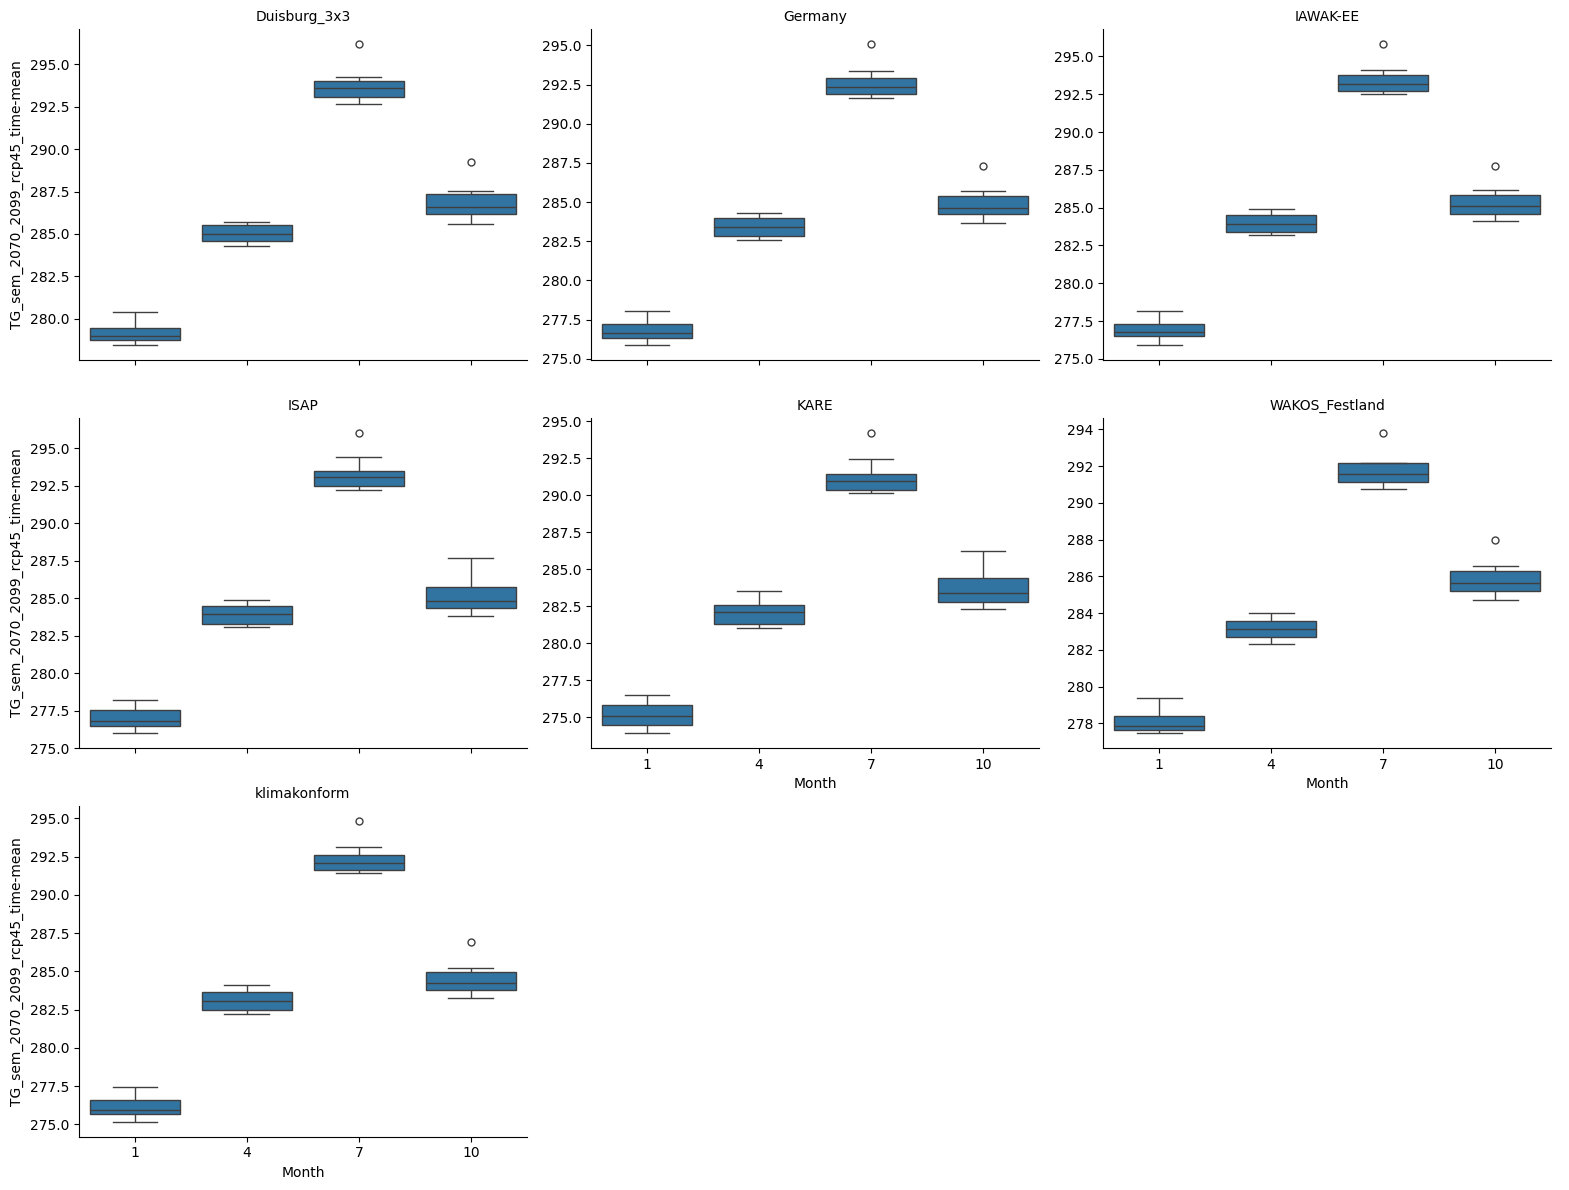

In [21]:
#box_value_col = next(
#    col for col in box_data.select_dtypes(include="number").columns
#    if col != "mid_month"
#)

value_col = "TG_sem_2070_2099_rcp45_time-mean"

g = sns.catplot(
    data=box_data,
    x="mid_month",
    y=value_col,
    col="region",
    col_wrap=3,
    kind="box",
    order=sorted(box_data["mid_month"].dropna().unique()),
    sharey=False,
    height=4,
    aspect=1.3
)

g.set_axis_labels("Month", value_col)
g.set_titles("{col_name}")
plt.tight_layout()
plt.show()

<DatetimeArray>
['1961-07-15 00:00:00', '1962-07-15 00:00:00', '1963-07-15 00:00:00',
 '1964-07-15 00:00:00', '1965-07-15 00:00:00', '1966-07-15 00:00:00',
 '1967-07-15 00:00:00', '1968-07-15 00:00:00', '1969-07-15 00:00:00',
 '1970-07-15 00:00:00',
 ...
 '2141-07-15 00:00:00', '2142-07-15 00:00:00', '2143-07-15 00:00:00',
 '2144-07-15 00:00:00', '2145-07-15 00:00:00', '2146-07-15 00:00:00',
 '2147-07-15 00:00:00', '2148-07-15 00:00:00', '2149-07-15 00:00:00',
 '2150-07-15 00:00:00']
Length: 190, dtype: datetime64[ns]


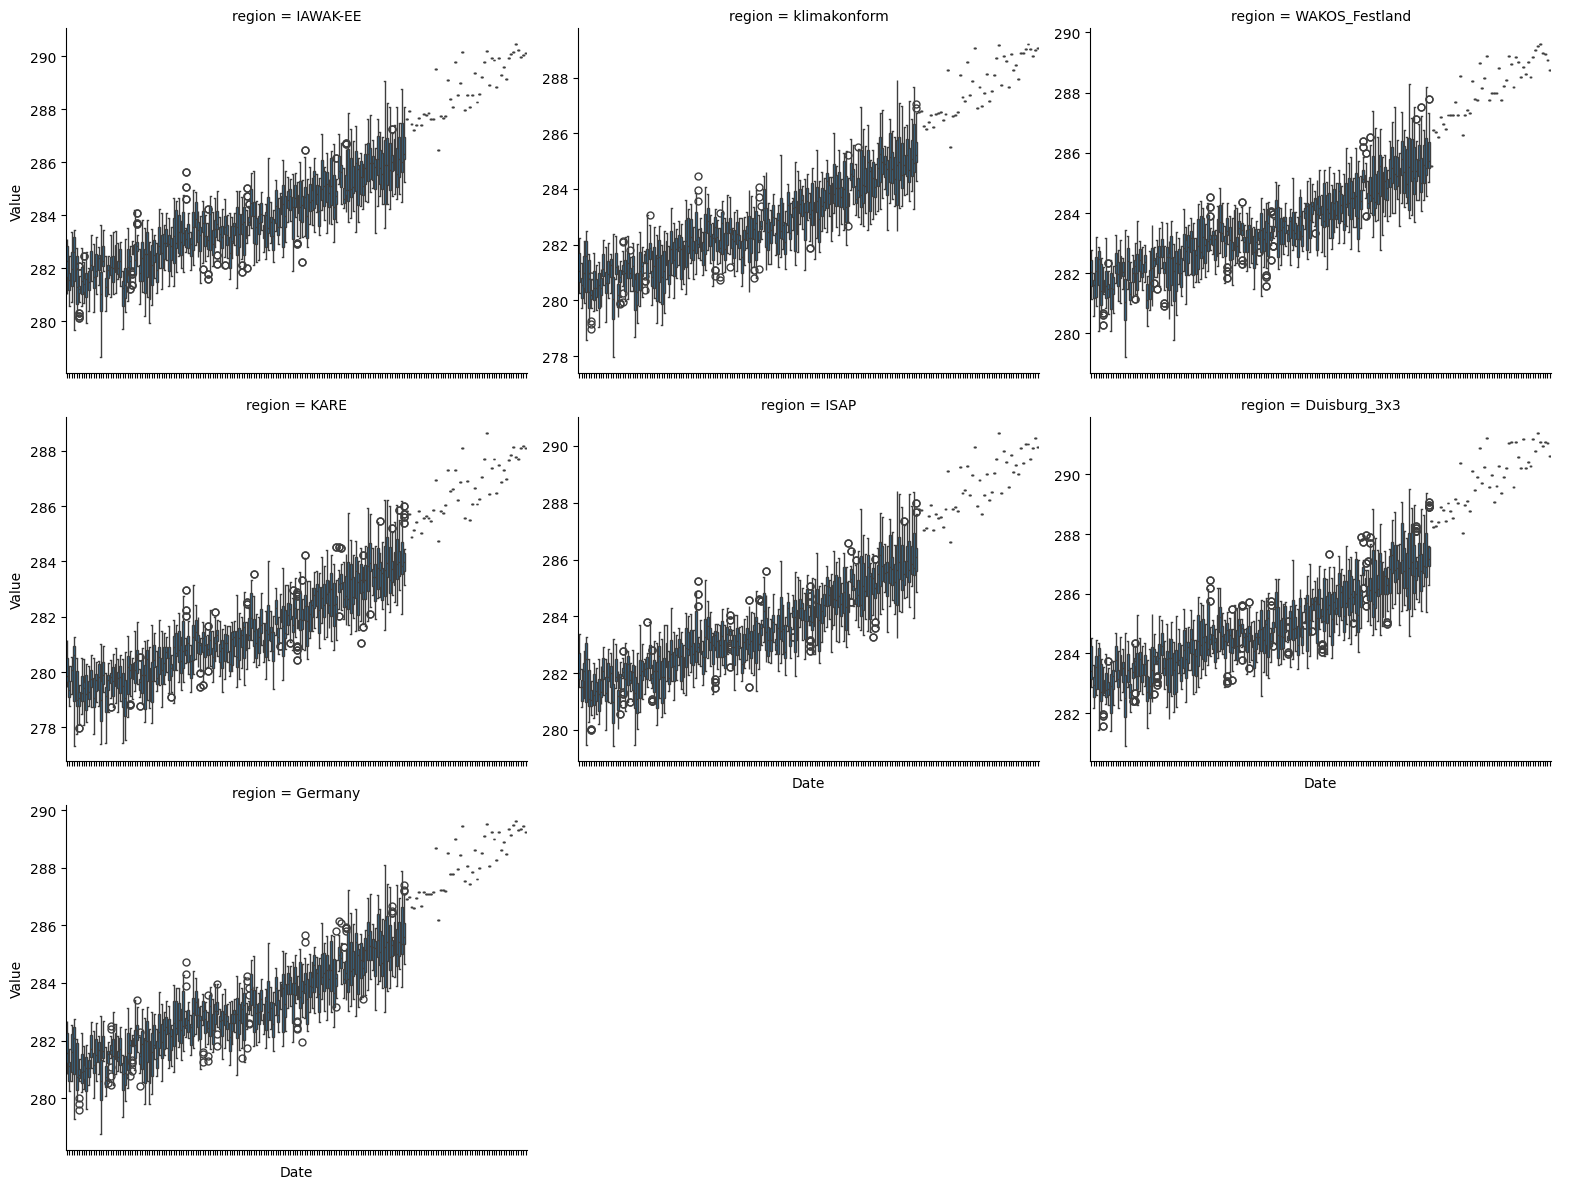

In [14]:
box_data = pd.read_csv(os.path.join(datadir, datafiles[3]))
box_data["date"] = pd.to_datetime(box_data["time"], errors="coerce")
box_data = box_data.dropna(subset=["date"])
print(box_data['date'].unique())
date_order = sorted(box_data["date"].unique())

g = sns.catplot(
    data=box_data,
    x="date",
    y="value",
    col="region",
    col_wrap=3,
    kind="box",
    order=date_order,
    sharey=False,
    height=4,
    aspect=1.3
)

g.set_xticklabels(rotation=45, ha="right")
g.set_axis_labels("Date", "Value")
plt.tight_layout()
plt.show()

In [10]:
import seaborn as sns

import matplotlib.pyplot as plt

plot_data = pd.concat(
    [pd.read_csv(os.path.join(datadir, datafiles[i])) for i in (0, 4)],
    ignore_index=True
)

# Get the scenario from the realization name if the column is missing.
if "scenario" not in plot_data.columns:
    plot_data["scenario"] = plot_data["realization"].str.extract(
        r"(?i)(ssp370|rcp85)", expand=False
    )

plot_data["scenario"] = plot_data["scenario"].astype(str).str.lower()
plot_data = plot_data[plot_data["scenario"].isin(["ssp370", "rcp85"])].copy()

# Use an existing date column, or combine year and season.
if "date" in plot_data.columns:
    date_col = "date"
else:
    date_col = "date"
    plot_data[date_col] = (
        plot_data["year"].astype(str) + "-" + plot_data["season"].astype(str)
    )

value_col = "RRm" if "RRm" in plot_data.columns else "TG"

g = sns.catplot(
    data=plot_data,
    x=date_col,
    y=value_col,
    hue="scenario",
    col="region",
    col_wrap=3,
    kind="box",
    sharey=False,
    height=4,
    aspect=1.3
)

g.set_xticklabels(rotation=45, ha="right")
g.set_axis_labels("Date", value_col)
plt.tight_layout()
plt.show()

KeyError: 'year'